# 3. Commodity prices and the budget

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/energy-grid-technology/procurement-spend-analytics/notebooks/03_commodity_prices_and_budget.ipynb)

Two questions: where are copper, electrical steel, hot-rolled steel, aluminium and transformer oil heading, and how much of a move reaches Havelwerk's purchase prices?

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "energy-grid-technology/procurement-spend-analytics"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlsxwriter", "python-pptx"], check=True)
else:
    here = Path.cwd()
    while not (here / "src" / "spendcube").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: procurement-spend-analytics


In [2]:
import json
from spendcube import sources as S, suppliers as SU, quality as Q, cube as C, analytics as A, forecast as F, profiling
from spendcube.pipeline import load_indices
raw = S.read_raw()
key = json.loads(Path("data/raw/_answer_key.json").read_text())
recs, merges, review = SU.match(SU.stack_masters(raw))
harmonised = S.harmonise(raw)
lines, clean_log = C.clean(harmonised, recs, raw)
tables = C.build(lines, SU.golden_records(recs))
con = C.to_sqlite(tables)
print({k: len(v) for k, v in raw.items()})

{'erp_a_ekpo': 10703, 'erp_a_lfa1': 114, 'erp_b_orders': 3414, 'erp_b_suppliers': 53, 'goods_receipts': 13147, 'quality_notifications': 178, 'contracts': 38, 'commodity_indices': 94}


In [3]:
ind = load_indices(raw)
bt = F.backtest(ind)
s = F.summarise(bt)
s.filter(like="_mape")

model,ar_ridge_mape,drift_mape,holt_damped_mape,naive_mape,seasonal_naive_mape
index,,,,,
aluminium,0.0560,0.0596,0.0580,0.0571,0.0818
copper,0.0724,0.0715,0.0747,0.0738,0.1178
goes,0.0538,0.0541,0.0529,0.0521,0.0788
oil,0.0885,0.0974,0.0893,0.0876,0.0944
steel_hrc,0.1211,0.1262,0.1267,0.1170,0.1849


Mean absolute percentage error over all horizons, refitting every month from October 2023. Skill is the improvement over the naive forecast:

In [4]:
s.filter(like="_skill").join(s.chosen)

,ar_ridge_skill,drift_skill,holt_damped_skill,seasonal_naive_skill,chosen
index,,,,,
aluminium,0.020,-0.044,-0.016,-0.433,naive
copper,0.018,0.031,-0.013,-0.597,naive
goes,-0.032,-0.038,-0.014,-0.512,naive
oil,-0.010,-0.111,-0.019,-0.078,naive
steel_hrc,-0.035,-0.078,-0.083,-0.580,naive


No model beats the naive forecast by more than 5% for any index, so the outlook keeps the last value and the useful part is the band. The backtest checks that the 80% band holds about 80% of outcomes:

In [5]:
print("coverage:", round(F.coverage(bt, ind, s.chosen.to_dict()), 3))
bt.groupby(["model", "h"]).ape.mean().unstack().round(3)

coverage: 0.804


h,1,2,3,4,5,6
model,,,,,,
ar_ridge,0.044,0.063,0.076,0.090,0.097,0.106
drift,0.044,0.065,0.079,0.094,0.103,0.113
holt_damped,0.045,0.064,0.078,0.091,0.100,0.111
naive,0.044,0.063,0.076,0.089,0.096,0.104
seasonal_naive,0.062,0.088,0.109,0.128,0.139,0.153


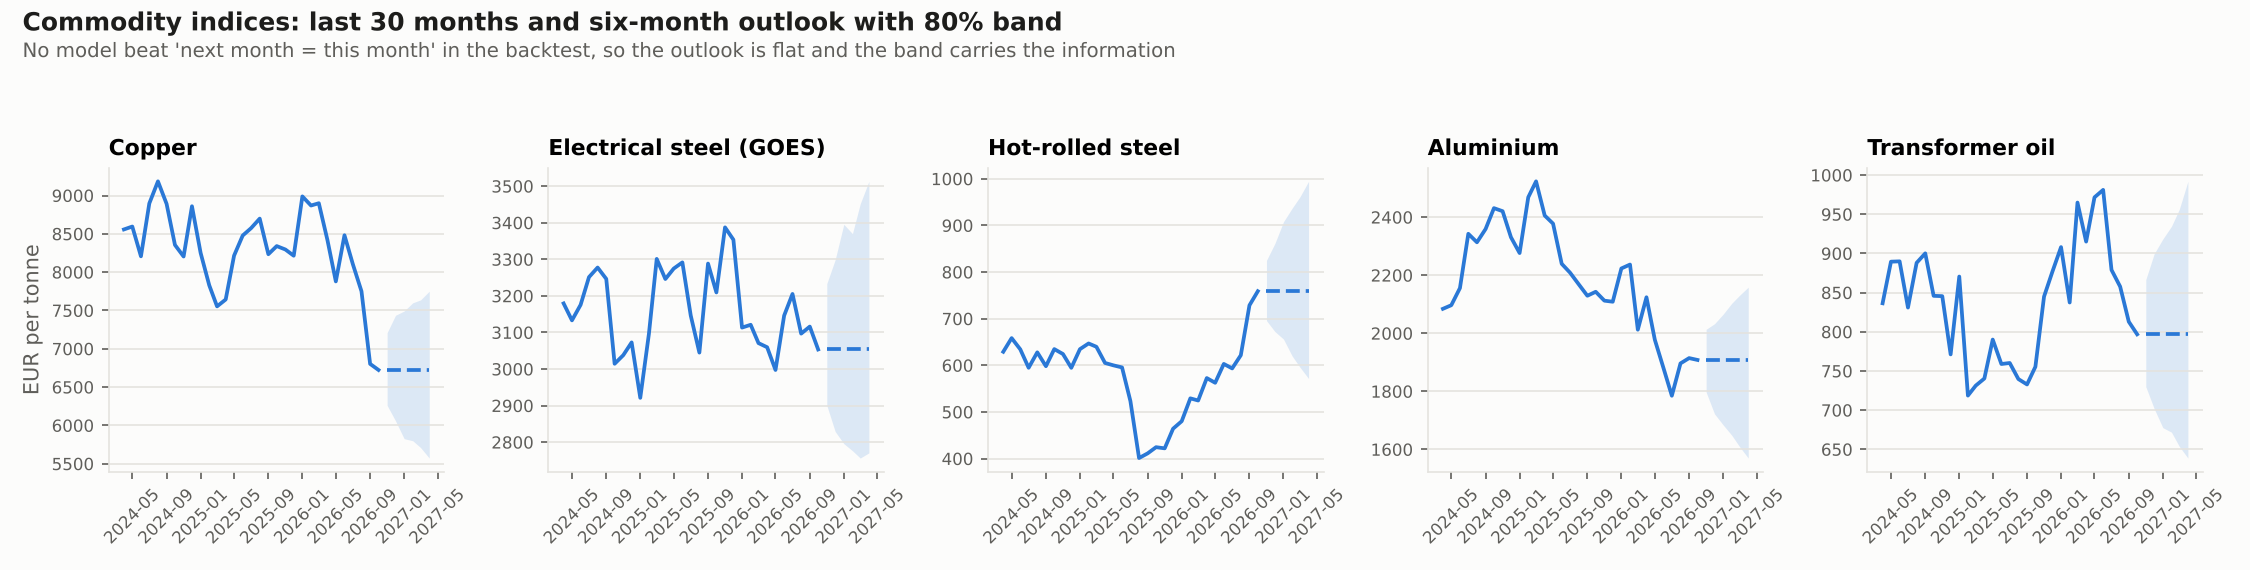

In [6]:
display(Image("outputs/figures/commodity_forecast.png"))

## Pass-through to purchase prices

Regressing each category's relative price on the relative index at lags 0 to 3 recovers how the supply contracts work: the share of the price that follows the index and the delay.

In [7]:
pt = F.pass_through(tables["fact_po_line"], ind)
pt

,category,index,lag_months,pass_through,r2
0,CU,copper,1,0.733492,0.996416
1,ES,goes,2,0.669114,0.996213
2,ST,steel_hrc,1,0.528049,0.998470
3,AL,aluminium,1,0.562201,0.978725
4,OI,oil,1,0.479869,0.974077


In [8]:
fc = F.forecast(ind, s.chosen.to_dict())
F.budget_impact(tables["fact_po_line"], ind, fc, pt).round(0)

,category,avg_price_change_expected,avg_price_change_high,avg_price_change_low,impact_eur_6m_expected,impact_eur_6m_high,impact_eur_6m_low,monthly_spend_eur
0,AL,0.0,0.0,-0.0,36547.0,150915.0,-116450.0,470707.0
1,CU,-0.0,-0.0,-0.0,-3365037.0,-820926.0,-6043520.0,6965845.0
2,ES,-0.0,0.0,-0.0,-176804.0,197025.0,-490973.0,1622827.0
3,OI,-0.0,0.0,-0.0,-17330.0,14859.0,-47185.0,96396.0
4,ST,0.0,0.0,0.0,783552.0,1604405.0,132241.0,1444042.0
